# TLE test

In [1]:
from datetime import datetime, timedelta
import numpy as np
import json
import astropy.time
import astropy.units as u
import pandas as pd

from sgp4.propagation import sgp4 as sgprop
from sgp4.io import twoline2rv
from sgp4.earth_gravity import wgs72, wgs84
import astropy.coordinates
import astropy.time
import astropy.units as u

import matplotlib.pyplot as plt

from scipy.integrate import DOP853, solve_ivp

import perturbations

In [2]:
# find the object position at those times
def propTLEtoJDs( l1, l2, jds ):
    tleo = twoline2rv( l1, l2, wgs72 )
    offs = ( np.array(jds) - tleo.jdsatepoch ) * 1440
    def propToJd( off_m ):
        return np.hstack( sgprop( tleo, off_m ) )
    return np.vstack( [propToJd(X) for X in offs ] )

def propTLEtoGCRS( l1, l2, datetimes ):
    atime    = astropy.time.Time( datetimes )
    eph_teme = propTLEtoJDs( *TLE, atime.jd )
    apy_teme = astropy.coordinates.TEME(
                x = eph_teme[:,0] * u.km,
                y = eph_teme[:,1] * u.km,
                z = eph_teme[:,2] * u.km,
                v_x = eph_teme[:,3] * u.km/u.s,
                v_y = eph_teme[:,4] * u.km/u.s,
                v_z = eph_teme[:,5] * u.km/u.s,
                obstime = atime )
    apy_gcrs = apy_teme.transform_to( astropy.coordinates.GCRS( obstime=atime ) )
    P = apy_gcrs.cartesian.xyz.to_value(u.km).T
    V = apy_gcrs.velocity.d_xyz.to_value(u.km/u.s).T
    return np.hstack((P,V))


In [3]:
TLE = ('1 27424U 02022A   26302.24662367  .00000407  00000-0  90607-4 0  9991',
       '2 27424  98.4469 274.3380 0000825  95.3867 321.3749 14.62255118302864')

TLE = ('1 39070U 13004A   26301.97757641  .00000086  00000+0  00000+0 0  9997',
       '2 39070   3.7292  33.1865 0002075  37.9969 143.7174  1.00268625 48039')

TLE = ('1 45854U 20041A   26301.59769463 -.00000067  00000+0  00000+0 0  9996',
       '2 45854  56.7470  23.7791 0069703 207.3791 326.5643  2.00572229 46716')

TLE = ('1 37238U 10065B   26300.85260892  .00000008  00000+0  00000+0 0  9992',
       '2 37238   0.0194 267.8522 0002531 310.4043 190.9230  1.00273262 54575')

tleo    = twoline2rv( *TLE, wgs72 )
tle_epoch = pd.to_datetime( tleo.jdsatepoch, origin='julian', unit='D')
dates   = pd.date_range( tle_epoch, tle_epoch + pd.Timedelta(days=7), freq='5min')
atimes  = astropy.time.Time( dates )
off_s   = (atimes - atimes[0]).jd * 86400
tle_eph = propTLEtoGCRS( *TLE, dates )

P = perturbations.perturbations( atimes[0], atimes[-1] )
# P.addAll()
# P.addMoon()
# P.addSun()
P.addJ2()
P.addJ3()
# P.addSRP()
# P.addAtmosphereExponential()

init_sv = tle_eph[0,:]

In [4]:
result = solve_ivp(
    P,
    (0, 86400 * 7.01),
    init_sv,
    args=(),
    rtol=1e-10,
    atol=1e-12,
    method=DOP853,
    dense_output=True,
    events=None,
)

/home/woodkn1/DND/lib/python3.10/site-packages/poliastro/core/perturbations.py:38: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 1, 'A', False, aligned=True))
  r = norm(r_vec)


In [5]:
int_eph = result.sol( off_s ).T
err     = int_eph - tle_eph

Text(0, 0.5, 'Total position error (km)')

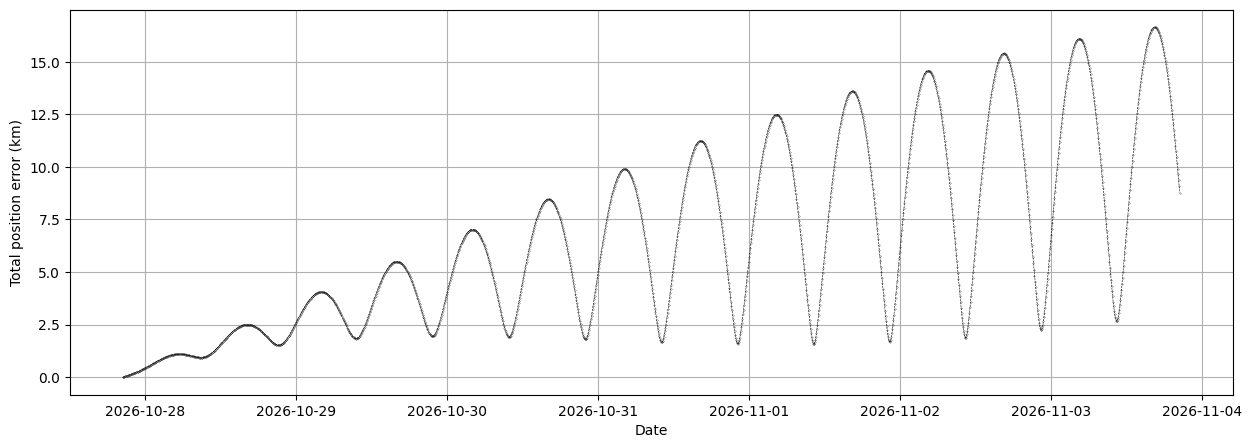

In [6]:
err = int_eph - tle_eph
plt.close('all')
plt.figure( figsize=(15,5) )
plt.plot( dates, np.linalg.norm( err[:,:3], axis=1 ), '--.', color='k', markersize=0.4, linewidth=0.4 )
plt.grid()
plt.xlabel('Date' )
plt.ylabel('Total position error (km)')